#ATIVIDADE DIDÁTICA: INFERÊNCIA ESTATÍSTICA APLICADA AO CONTROLE DE QUALIDADE DE ALIMENTOS - Resolução do Grupo 8


## LCE0212 – Estatística Aplicada às Ciências dos Alimentos
## Prof. Dr. Cristian Marcelo Villegas Lobos
### Tema: Testes de hipóteses aplicados à Ciência dos Alimentos.

Data da atividade: 09/11/2026

## Integrates
* **Karin Santos** - Nº USP: 15674699
* **Larissa Taffarel** - Nº USP: 14669771


### Questão 2: Teor de proteína em um produto lácteo

**1. Variável de interesse e Parâmetro populacional:**
* **Variável aleatória ($X$):** Teor de proteína por porção (em gramas).
* **Parâmetro populacional ($\mu$):** Teor médio de proteína por porção na nova formulação.

**2. Formulação das Hipóteses:**
* $H_0: \mu \le 8,0$ g (O teor médio de proteína não aumentou)
* $H_1: \mu > 8,0$ g (O teor médio aumentou - Teste Unilateral Direito)

**3. Procedimento estatístico apropriado:**
* Teste t de Student para uma média populacional, pois a variância populacional é desconhecida, a amostra é pequena ($n = 16$), e assume-se que a característica segue distribuição aproximadamente Normal.

---

---

Graus de Liberdade: 15
Estatística de Teste (t observado): 2.0000
Valor-p: 0.0320


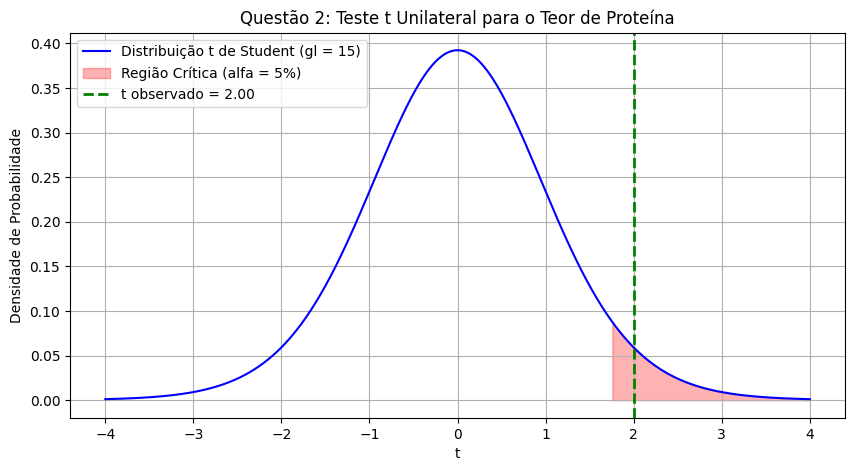

In [7]:
# --- Dados fornecidos pela Questão 2 ---
mu_0 = 8.0       # Teor de proteína sob H0 (em gramas por porção)
n = 16           # Tamanho da amostra
x_bar = 8.4      # Média amostral observada
s = 0.8          # Desvio-padrão amostral (s)
alpha = 0.05     # Nível de significância (5%)
df = n - 1       # Graus de liberdade para a distribuição t de Student (n - 1)

# --- Cálculo da Estatística de Teste (t observado) ---
# Como o desvio-padrão populacional é desconhecido, usamos o Teste t:
# t = (Média Amostral - Média sob H0) / Erro Padrão Amostral
erro_padrao_amostral = s / np.sqrt(n)
t_obs = (x_bar - mu_0) / erro_padrao_amostral

# --- Cálculo do Valor-p (Teste Unilateral Direito) ---
# Queremos saber se o teor é significativamente maior (cauda superior direita):
# p-valor = P(T_df >= t_obs) = 1 - CDF_t(t_obs, df)
p_value = 1 - stats.t.cdf(t_obs, df)

print(f"Graus de Liberdade: {df}")
print(f"Estatística de Teste (t observado): {t_obs:.4f}")
print(f"Valor-p: {p_value:.4f}")

# --- Geração do Gráfico de Distribuição ---
x = np.linspace(-4, 4, 1000)
y = stats.t.pdf(x, df)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x, y, 'b-', label=f'Distribuição t de Student (gl = {df})')

# Região Crítica (Unilateral Direito)
t_crit = stats.t.ppf(1 - alpha, df)
# Preenche a área de rejeição na cauda direita em vermelho
ax.fill_between(x, 0, y, where=(x >= t_crit), color='red', alpha=0.3, label='Região Crítica (alfa = 5%)')
# Destaca o valor observado calculado na amostra
ax.axvline(t_obs, color='green', linestyle='--', linewidth=2, label=f't observado = {t_obs:.2f}')

ax.set_title('Questão 2: Teste t Unilateral para o Teor de Proteína')
ax.set_xlabel('t')
ax.set_ylabel('Densidade de Probabilidade')
ax.legend()
plt.grid(True)
plt.show()

#### **Resultados e Conclusão da Questão 2**

* **Graus de Liberdade ($df$):** $15$
* **Estatística de Teste ($t_{\text{obs}}$):** $2,0000$
* **Valor-p:** $0,0320$

**Decisão Estatística:**
Como o valor-p ($0,0320$) é menor do que o nível de significância de $\alpha = 5\%$ ($0,05$), **rejeitamos a hipótese nula ($H_0$)**.

**Interpretação no Contexto da Ciência de Alimentos:**
Há evidências estatísticas de que o teor médio de proteína do produto lácteo após a alteração da formulação é superior a $8,0$ g por porção. Isso indica que a mudança de processo/ingredientes foi eficaz em enriquecer o produto. **A equipe de desenvolvimento pode validar a nova rotulagem nutricional do produto proteico.**

In [12]:
# Célula desativada - Conteúdo removido conforme solicitação

---

Estatística de Teste (Qui-quadrado observado): 30.4000
Valores Críticos: [8.9065, 32.8523]
Valor-p: 0.0938


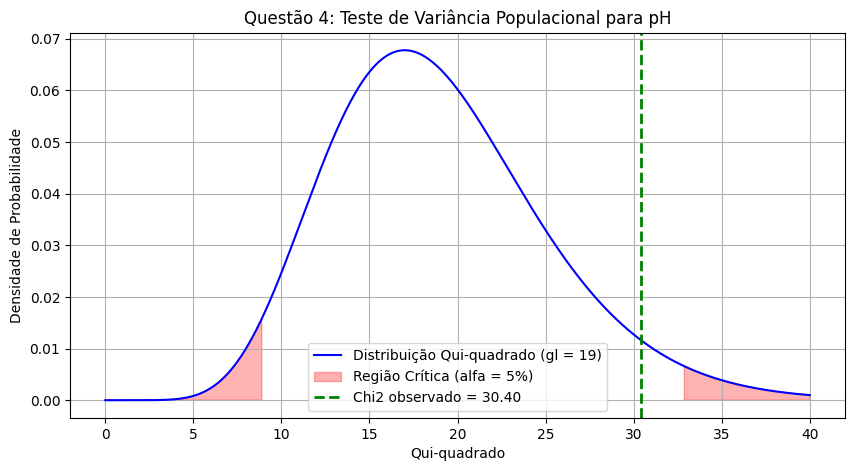

In [9]:
# --- Dados fornecidos pela Questão 4 ---
sigma2_0 = 0.04   # Variância histórica estabelecida como referência sob H0
n = 20            # Tamanho da amostra
s2 = 0.064        # Variância amostral observada
alpha = 0.05      # Nível de significância (5%)
df = n - 1        # Graus de liberdade (n - 1 = 19)

# --- Cálculo da Estatística de Teste (Qui-quadrado observado) ---
# Estatística baseada na razão entre variância amostral e populacional teórica:
# Chi2 = (n - 1) * s^2 / sigma_0^2
chi2_obs = (n - 1) * s2 / sigma2_0

# --- Cálculo do Valor-p (Teste Bilateral) ---
# Como a distribuição Qui-quadrado não é simétrica, calculamos o menor lado acumulado
# e multiplicamos por 2 para bicaudalizar o teste
cdf_val = stats.chi2.cdf(chi2_obs, df)
p_value = 2 * min(cdf_val, 1 - cdf_val)

# --- Determinação dos Valores Críticos na tabela Qui-quadrado ---
chi2_crit_inf = stats.chi2.ppf(alpha / 2, df)
chi2_crit_sup = stats.chi2.ppf(1 - alpha / 2, df)

print(f"Estatística de Teste (Qui-quadrado observado): {chi2_obs:.4f}")
print(f"Valores Críticos: [{chi2_crit_inf:.4f}, {chi2_crit_sup:.4f}]")
print(f"Valor-p: {p_value:.4f}")

# --- Geração do Gráfico de Distribuição ---
x = np.linspace(0, 40, 1000)
y = stats.chi2.pdf(x, df)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x, y, 'b-', label=f'Distribuição Qui-quadrado (gl = {df})')

# Preenche as áreas críticas em vermelho
ax.fill_between(x, 0, y, where=(x <= chi2_crit_inf) | (x >= chi2_crit_sup), color='red', alpha=0.3, label='Região Crítica (alfa = 5%)')
# Destaca o valor observado calculado na amostra
ax.axvline(chi2_obs, color='green', linestyle='--', linewidth=2, label=f'Chi2 observado = {chi2_obs:.2f}')

ax.set_title('Questão 4: Teste de Variância Populacional para pH')
ax.set_xlabel('Qui-quadrado')
ax.set_ylabel('Densidade de Probabilidade')
ax.legend()
plt.grid(True)
plt.show()

#### **Resultados e Conclusão da Questão 4**

* **Estatística de Teste ($\chi^2_{\text{obs}}$):** $30,4000$
* **Região Crítica de Aceitação ($\_0$):** $[8,9065 \le \chi^2 \le 32,8523]$
* **Valor-p:** $0,0938$

**Decisão Estatística:**
Como o valor-p ($0,0938$) é maior do que o nível de significância de $\alpha = 5\%$ ($0,05$), e a estatística observada está dentro dos limites críticos, **não rejeitamos a hipótese nula ($H_0$)**.

**Interpretação no Contexto da Ciência de Alimentos:**
Não há evidências estatísticas suficientes para afirmar que a variabilidade do pH do lote recente é diferente da variância histórica de referência de $0,04$. Embora a variância amostral tenha sido de $0,064$, essa flutuação é explicada pelo acaso amostral. **O processo de fermentação é considerado sob controle em termos de uniformidade de pH.**

---

### Questão 5: Proporção de produtos com não conformidade microbiológica

**1. Variável de interesse e Parâmetro:**
* **Variável aleatória ($X$):** Presença de não conformidade microbiológica na unidade (Binária).
* **Parâmetro populacional ($p$):** Proporção populacional de unidades não conformes no lote.

**2. Formulação das Hipóteses:**
* $H_0: p \le 0,05$ (A proporção de não conformes está dentro do limite aceitável)
* $H_1: p > 0,05$ (A proporção excede o limite de 5% - Teste Unilateral Direito)

**3. Procedimento estatístico apropriado:**
* Teste Z para uma proporção populacional por aproximação normal.

Proporção amostral (p chapéu): 0.0800 (8.00%)
Estatística de Teste (Z observado): 1.9467
Valor-p: 0.0258


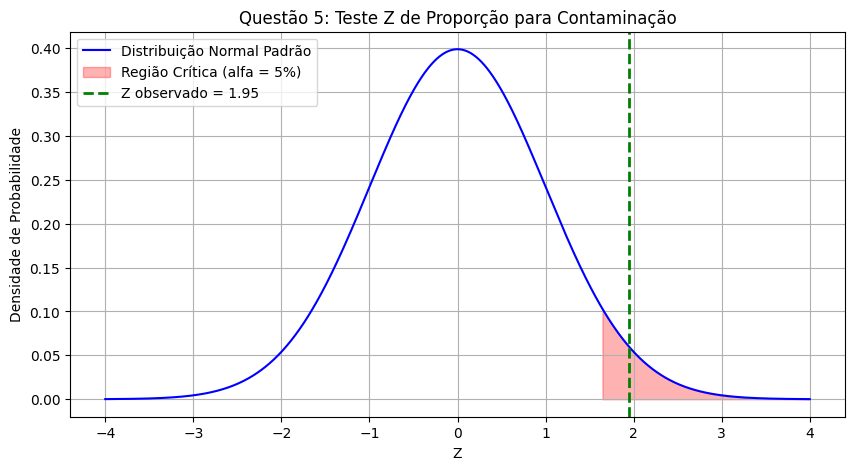

In [10]:
# --- Dados fornecidos pela Questão 5 ---
p_0 = 0.05               # Proporção máxima tolerável sob H0 (5%)
n = 200                  # Tamanho total da amostra de unidades inspecionadas
x_non_conforming = 16    # Unidades classificadas como não conformes
alpha = 0.05             # Nível de significância (5%)

# --- Cálculo da Proporção Amostral (p chapéu) ---
p_hat = x_non_conforming / n

# --- Cálculo da Estatística de Teste (Z observado) ---
# Como o tamanho amostral é grande, usamos a aproximação normal do Teste Z:
# Z = (p_hat - p_0) / raiz( p_0 * (1 - p_0) / n )
z_obs = (p_hat - p_0) / np.sqrt((p_0 * (1 - p_0)) / n)

# --- Cálculo do Valor-p (Teste Unilateral Direito) ---
# Desejamos provar que a contaminação excede o aceitável (cauda superior):
# p-valor = P(Z >= z_obs) = 1 - CDF_Z(z_obs)
p_value = 1 - stats.norm.cdf(z_obs)

print(f"Proporção amostral (p chapéu): {p_hat:.4f} ({p_hat*100:.2f}%)")
print(f"Estatística de Teste (Z observado): {z_obs:.4f}")
print(f"Valor-p: {p_value:.4f}")

# --- Geração do Gráfico de Distribuição ---
x = np.linspace(-4, 4, 1000)
y = stats.norm.pdf(x)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x, y, 'b-', label='Distribuição Normal Padrão')

# Região Crítica de cauda direita para alfa = 5%
z_crit = stats.norm.ppf(1 - alpha)
# Preenche a cauda de rejeição em vermelho
ax.fill_between(x, 0, y, where=(x >= z_crit), color='red', alpha=0.3, label='Região Crítica (alfa = 5%)')
# Destaca o valor observado calculado na amostra
ax.axvline(z_obs, color='green', linestyle='--', linewidth=2, label=f'Z observado = {z_obs:.2f}')

ax.set_title('Questão 5: Teste Z de Proporção para Contaminação')
ax.set_xlabel('Z')
ax.set_ylabel('Densidade de Probabilidade')
ax.legend()
plt.grid(True)
plt.show()

#### **Resultados e Conclusão da Questão 5**

* **Proporção Amostral ($\hat{p}$):** $0,0800$ ($8,00\%$)
* **Estatística de Teste ($Z_{\text{obs}}$):** $1,9467$
* **Valor-p:** $0,0258$

**Decisão Estatística:**
Como o valor-p ($0,0258$) é menor do que o nível de significância de $\alpha = 5\%$ ($0,05$), **rejeitamos a hipótese nula ($H_0$)**.

**Interpretação no Contexto da Ciência de Alimentos:**
A proporção de unidades não conformes do lote avaliado é estatisticamente superior ao limite aceitável de $5\%$. Essa taxa de contaminação expõe a marca a riscos regulatórios e de saúde pública. **A recomendação técnica é reter o lote de produção e realizar uma auditoria completa nos processos de higienização, temperatura e boas práticas de fabricação (BPF).**

### **Resumo Executivo do Controle de Qualidade (Questões Mantidas)**

Este estudo consolidado apresenta as análises estatísticas para os processos produtivos em avaliação:

* **Teor de Proteína (Questão 2)**: Rejeitamos a hipótese nula ($p = 0,0320$). Há evidências estatísticas significativas de que o teor médio de proteína do produto lácteo é superior a $8,0$ g por porção após a nova formulação, confirmando o ganho proteico planejado pela engenharia de produto.

* **Variabilidade do pH (Questão 4)**: Não rejeitamos a hipótese nula ($p = 0,0938$). A variação dos valores de pH do lote recente se mantém estatisticamente estável e dentro da variância de referência de $0,04$, indicando excelente uniformidade no processo de fermentação.

* **Não Conformidade Microbiológica (Questão 5)**: Rejeitamos a hipótese nula ($p = 0,0258$). A proporção amostral de $8\%$ de itens contaminados excede de forma estatisticamente significante a tolerância máxima permitida de $5\%$. Recomenda-se a retenção imediata do lote e auditoria de higiene das Boas Práticas de Fabricação (BPF).